In [1]:
#Setup: imports (everything needed is pre-installed on Colab)
import re, nltk, numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics.pairwise import cosine_similarity

for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

In [2]:
#Requirement 1: labelled dataset
DATA = {
 "symptoms": [
  "What are the symptoms of a heart attack?",
  "I get chest pain when I climb stairs, what could it be?",
  "Why does my heart beat so fast sometimes?",
  "What are the warning signs of heart failure?",
  "Is shortness of breath a sign of heart problems?",
  "My heart skips beats, is that dangerous?",
  "What does angina feel like?",
  "Why are my ankles swollen, is it related to my heart?",
  "Can heart disease cause dizziness and fatigue?",
  "What are the early signs of a weak heart?",
  "Is left arm pain a sign of a heart problem?",
  "Why do I feel breathless when I walk uphill?",
  "What does it feel like when your heart is failing?",
  "Can a racing pulse be a symptom of heart disease?",
  "I feel pressure in my chest when I walk fast, what does it mean?",
  "What are the signs of an irregular heartbeat?",
  "Why do I feel tired and weak all the time, is it my heart?"],
 "risk_factors": [
  "What are the risk factors for heart disease?",
  "Does high blood pressure increase the chance of a heart attack?",
  "Is smoking bad for my heart?",
  "Can diabetes cause heart disease?",
  "Does family history affect my risk of heart disease?",
  "Why is high cholesterol dangerous for the heart?",
  "Are obese people more likely to get heart problems?",
  "Does stress cause heart disease?",
  "At what age does the risk of heart attack increase?",
  "Are men more at risk of heart disease than women?",
  "How does obesity affect the risk to my heart?",
  "Is high LDL cholesterol a major cause of heart attacks?",
  "What lifestyle choices make heart disease more likely?",
  "Does drinking alcohol raise my heart attack risk?",
  "Am I at higher risk of a heart attack if my father had one?",
  "Does sleeping too little increase heart risk?",
  "Is high blood sugar a risk for the heart?"],
 "prevention": [
  "How can I keep my heart healthy?",
  "What foods are good for heart health?",
  "How much exercise do I need to protect my heart?",
  "What diet should I follow to lower cholesterol?",
  "How can I reduce salt intake to protect my heart?",
  "Does quitting smoking improve heart health?",
  "How can I lower my blood pressure naturally?",
  "Can yoga and meditation help my heart?",
  "How can I prevent heart disease?",
  "Is walking every day good for the heart?",
  "What should I eat every day for a healthy heart?",
  "Which exercises are best for strengthening the heart?",
  "How can I reduce stress to protect my heart?",
  "What lifestyle changes help prevent a heart attack?",
  "Are oats and nuts good for lowering cholesterol?",
  "What can I do to stay heart healthy after 40?",
  "How can I take care of my heart every day?",
  "How can I keep my heart strong as I age?",
  "Give me a few tips for a healthy heart"],
 "medications": [
  "What do statins do for the heart?",
  "What are the side effects of beta blockers?",
  "Should I take aspirin daily for my heart?",
  "How do blood thinners work?",
  "What medicines are used to treat high blood pressure?",
  "What is nitroglycerin used for?",
  "Can I stop taking my heart tablets if I feel better?",
  "What is an ACE inhibitor?",
  "Which drugs are prescribed after a heart attack?",
  "Are there side effects of cholesterol lowering medicines?",
  "What is warfarin used for?",
  "What is the purpose of taking a statin?",
  "Do heart medicines have side effects?",
  "How long do I have to take blood pressure tablets?",
  "Is it safe to take aspirin with other heart drugs?",
  "What does a diuretic do for heart failure?",
  "What is the purpose of ACE inhibitors?",
  "Is it okay to stop my medicines when my reports look normal?",
  "Do I need to keep taking my heart pills for life?"],
 "diagnostic_tests": [
  "What is an ECG test?",
  "How is heart disease diagnosed?",
  "What happens during a heart stress test?",
  "What is an echocardiogram?",
  "What does a lipid profile test measure?",
  "How is an angiography performed?",
  "Which blood test shows a heart attack?",
  "What is a normal blood pressure reading?",
  "When should I get my heart checked by a cardiologist?",
  "What is a Holter monitor?",
  "How does an echocardiogram work?",
  "How is a treadmill test done?",
  "What is a CT scan of the heart?",
  "How do doctors check for blocked arteries?",
  "What does a troponin test show?",
  "Which tests are done to check heart health?",
  "How often should I check my cholesterol levels?",
  "What is an ECG and what does it detect?",
  "Why do doctors ask for an ECG?",
  "Is an ECG painful?"],
 "emergency": [
  "I have severe chest pain right now, what should I do?",
  "My father collapsed and is not breathing, help!",
  "Chest pain spreading to my left arm and jaw, is this a heart attack?",
  "Someone is having a heart attack, what do I do?",
  "I feel crushing pressure in my chest and I am sweating heavily",
  "How do I perform CPR on an unconscious person?",
  "Call an ambulance, I think I am having a cardiac arrest",
  "I fainted and my chest hurts badly, is it an emergency?",
  "What first aid should I give for a sudden heart attack?",
  "My chest pain is not going away and I cannot breathe properly",
  "Help, my husband is clutching his chest and sweating, what do I do?",
  "Someone just fell unconscious, how do I start CPR?",
  "Should I go to hospital immediately for chest pain that radiates to my jaw?",
  "My friend is gasping and turning blue, call for help",
  "Sudden severe chest pressure with sweating and vomiting, what to do now?",
  "What do I do if a person stops breathing and has no pulse?",
  "I think my grandfather is having a stroke or heart attack, help"],
}
df = pd.DataFrame([(q, i) for i, qs in DATA.items() for q in qs], columns=["query", "intent"])
print(f"Total queries: {len(df)} | Intents: {df.intent.nunique()}")
print(df.intent.value_counts())
df.sample(6, random_state=1)

Total queries: 109 | Intents: 6
intent
diagnostic_tests    20
prevention          19
medications         19
symptoms            17
risk_factors        17
emergency           17
Name: count, dtype: int64


,query,intent
100,What first aid should I give for a sudden hear...,emergency
90,Why do doctors ask for an ECG?,diagnostic_tests
92,"I have severe chest pain right now, what shoul...",emergency
89,What is an ECG and what does it detect?,diagnostic_tests
101,My chest pain is not going away and I cannot b...,emergency
55,Should I take aspirin daily for my heart?,medications


In [3]:
#Requirement 2: taxonomy
TAXONOMY = {
 "Heart Conditions": ["Coronary Artery Disease", "Heart Failure", "Arrhythmia", "Hypertension"],
 "Symptoms and Warning Signs": ["Common Symptoms", "Emergency Warning Signs"],
 "Risk Factors": ["Modifiable (smoking, diet, inactivity)", "Non-modifiable (age, genetics, sex)"],
 "Prevention and Lifestyle": ["Diet and Nutrition", "Physical Activity", "Stress and Sleep"],
 "Diagnosis and Tests": ["Non-invasive (ECG, Echo, Stress test)", "Blood tests (Lipid, Troponin)", "Invasive (Angiography)"],
 "Treatment and Medication": ["Drug Therapy", "Procedures (Stent, Bypass)"],
}
print("Heart Health Taxonomy")
for major, subs in TAXONOMY.items():
    print(f"|-- {major}")
    for s in subs: print(f"|     |-- {s}")

Heart Health Taxonomy
|-- Heart Conditions
|     |-- Coronary Artery Disease
|     |-- Heart Failure
|     |-- Arrhythmia
|     |-- Hypertension
|-- Symptoms and Warning Signs
|     |-- Common Symptoms
|     |-- Emergency Warning Signs
|-- Risk Factors
|     |-- Modifiable (smoking, diet, inactivity)
|     |-- Non-modifiable (age, genetics, sex)
|-- Prevention and Lifestyle
|     |-- Diet and Nutrition
|     |-- Physical Activity
|     |-- Stress and Sleep
|-- Diagnosis and Tests
|     |-- Non-invasive (ECG, Echo, Stress test)
|     |-- Blood tests (Lipid, Troponin)
|     |-- Invasive (Angiography)
|-- Treatment and Medication
|     |-- Drug Therapy
|     |-- Procedures (Stent, Bypass)


16 concepts, 18 relationships
Hypertension --[increases risk of]--> Heart Failure
Hypertension --[increases risk of]--> Stroke
High Cholesterol --[causes]--> Atherosclerosis
Atherosclerosis --[leads to]--> Coronary Artery Disease
Coronary Artery Disease --[can cause]--> Heart Attack
Coronary Artery Disease --[causes]--> Chest Pain
Smoking --[damages arteries, raises risk of]--> Atherosclerosis
Diabetes --[increases risk of]--> Coronary Artery Disease
Obesity --[contributes to]--> Hypertension
Physical Inactivity --[contributes to]--> Obesity
ECG --[detects]--> Arrhythmia
ECG --[helps diagnose]--> Heart Attack
Statins --[lower]--> High Cholesterol
Beta Blockers --[treat]--> Arrhythmia
Beta Blockers --[lower]--> Hypertension
Arrhythmia --[can increase risk of]--> Stroke
Heart Attack --[can lead to]--> Heart Failure
Hypertension --[damages]--> Atherosclerosis


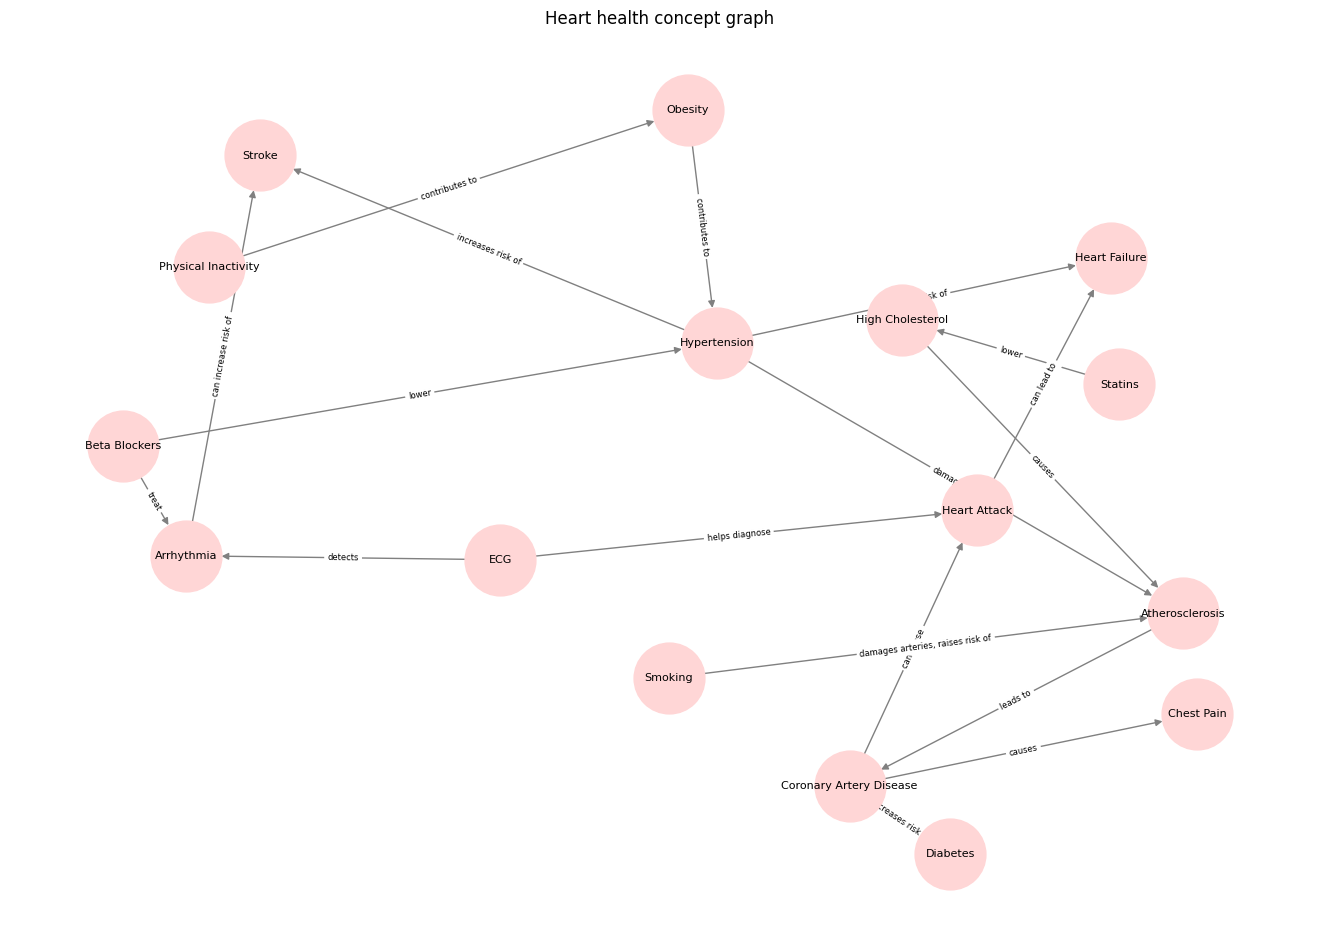

In [4]:
#Requirement 3: concepts and relationships (knowledge graph)
CONCEPTS = ["Hypertension", "High Cholesterol", "Atherosclerosis", "Coronary Artery Disease", "Heart Attack",
            "Heart Failure", "Arrhythmia", "Stroke", "Smoking", "Diabetes", "Obesity", "Physical Inactivity",
            "Chest Pain", "ECG", "Statins", "Beta Blockers"]

RELATIONS = [
 ("Hypertension", "increases risk of", "Heart Failure"),
 ("Hypertension", "increases risk of", "Stroke"),
 ("High Cholesterol", "causes", "Atherosclerosis"),
 ("Atherosclerosis", "leads to", "Coronary Artery Disease"),
 ("Coronary Artery Disease", "can cause", "Heart Attack"),
 ("Coronary Artery Disease", "causes", "Chest Pain"),
 ("Smoking", "damages arteries, raises risk of", "Atherosclerosis"),
 ("Diabetes", "increases risk of", "Coronary Artery Disease"),
 ("Obesity", "contributes to", "Hypertension"),
 ("Physical Inactivity", "contributes to", "Obesity"),
 ("ECG", "detects", "Arrhythmia"),
 ("ECG", "helps diagnose", "Heart Attack"),
 ("Statins", "lower", "High Cholesterol"),
 ("Beta Blockers", "treat", "Arrhythmia"),
 ("Beta Blockers", "lower", "Hypertension"),
 ("Arrhythmia", "can increase risk of", "Stroke"),
 ("Heart Attack", "can lead to", "Heart Failure"),
 ("Hypertension", "damages", "Atherosclerosis"),
]
G = nx.DiGraph()
G.add_nodes_from(CONCEPTS)
for a, r, b in RELATIONS: G.add_edge(a, b, label=r)
print(f"{G.number_of_nodes()} concepts, {G.number_of_edges()} relationships")
for a, r, b in RELATIONS: print(f"{a} --[{r}]--> {b}")

plt.figure(figsize=(13, 9))
pos = nx.spring_layout(G, seed=7, k=1.1)
nx.draw(G, pos, with_labels=True, node_color="#ffd6d6", node_size=2600, font_size=8, arrows=True, edge_color="gray")
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=6)
plt.title("Heart health concept graph"); plt.show()

In [5]:
#Requirement 4: preprocessing
tokenizer = RegexpTokenizer(r"[a-z]+")
STOP = set(stopwords.words("english")) - {"no", "not"}   # keep negations
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    tokens = tokenizer.tokenize(text.lower())                        # lowercase + tokenize
    tokens = [t for t in tokens if t not in STOP]                    # stopword removal
    return [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "n"), "v") for t in tokens]   # lemmatize

def clean(text): return " ".join(preprocess(text))

demo = "My heart skips beats and I am feeling dizzy while climbing stairs!"
print("Original :", demo)
print("Lowercase:", demo.lower())
print("Tokens   :", tokenizer.tokenize(demo.lower()))
print("Cleaned  :", preprocess(demo))
df["clean"] = df["query"].apply(clean)
df.head()

Original : My heart skips beats and I am feeling dizzy while climbing stairs!
Lowercase: my heart skips beats and i am feeling dizzy while climbing stairs!
Tokens   : ['my', 'heart', 'skips', 'beats', 'and', 'i', 'am', 'feeling', 'dizzy', 'while', 'climbing', 'stairs']
Cleaned  : ['heart', 'skip', 'beat', 'feel', 'dizzy', 'climb', 'stair']


,query,intent,clean
0,What are the symptoms of a heart attack?,symptoms,symptom heart attack
1,"I get chest pain when I climb stairs, what cou...",symptoms,get chest pain climb stair could
2,Why does my heart beat so fast sometimes?,symptoms,heart beat fast sometimes
3,What are the warning signs of heart failure?,symptoms,warn sign heart failure
4,Is shortness of breath a sign of heart problems?,symptoms,shortness breath sign heart problem


In [6]:
#Requirement 5: TF-IDF + Naive Bayes / Logistic Regression
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, stratify=df["intent"], random_state=42)

vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
Xtr = vectorizer.fit_transform(X_train)
Xte = vectorizer.transform(X_test)

models = {"Naive Bayes": MultinomialNB(alpha=0.3),
          "Logistic Regression": LogisticRegression(C=50, max_iter=2000)}
for name, m in models.items():
    m.fit(Xtr, y_train)
    print(f"{name:20s} test accuracy = {accuracy_score(y_test, m.predict(Xte)):.3f}")

clf = models["Logistic Regression"]   # chosen: gives class probabilities used for confidence rules
print("\nTrain size:", Xtr.shape[0], "| Test size:", Xte.shape[0], "| Features:", Xtr.shape[1])

Naive Bayes          test accuracy = 0.821
Logistic Regression  test accuracy = 0.821

Train size: 81 | Test size: 28 | Features: 409


Accuracy : 0.821
Precision: 0.873
Recall   : 0.821
F1-score : 0.817

                  precision    recall  f1-score   support

diagnostic_tests       1.00      0.60      0.75         5
       emergency       0.67      1.00      0.80         4
     medications       0.71      1.00      0.83         5
      prevention       1.00      0.80      0.89         5
    risk_factors       0.80      1.00      0.89         4
        symptoms       1.00      0.60      0.75         5

        accuracy                           0.82        28
       macro avg       0.86      0.83      0.82        28
    weighted avg       0.87      0.82      0.82        28



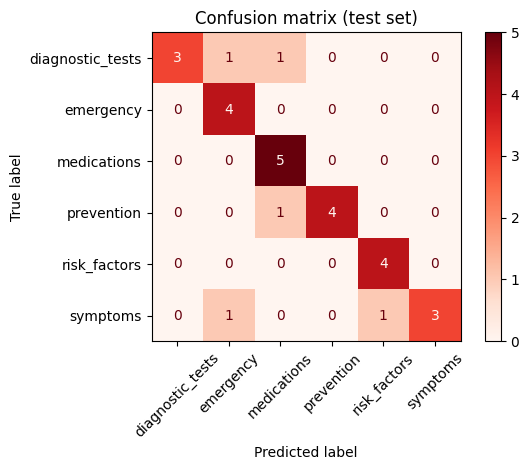

5-fold CV accuracy: [0.818 0.682 0.818 0.909 0.905] | mean = 0.826


In [7]:
#Requirement 6: evaluation
y_pred = clf.predict(Xte)
acc = accuracy_score(y_test, y_pred)
p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
print(f"Accuracy : {acc:.3f}\nPrecision: {p:.3f}\nRecall   : {r:.3f}\nF1-score : {f:.3f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(df.intent.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Reds", xticks_rotation=45)
plt.title("Confusion matrix (test set)"); plt.tight_layout(); plt.show()

full_X = vectorizer.transform(df["clean"])
cv = cross_val_score(LogisticRegression(C=50, max_iter=2000), full_X, df["intent"], cv=5)
print("5-fold CV accuracy:", cv.round(3), "| mean =", cv.mean().round(3))

In [8]:
#Requirement 7: knowledge base
KB = {
 "symptoms": [
  ("overview", "symptoms signs heart problem",
   "Common heart-related symptoms include chest pain or pressure, shortness of breath, palpitations (racing or irregular heartbeat), unusual tiredness, dizziness and swelling of the ankles or feet. These can have other causes too, so new or persistent symptoms should be checked by a doctor."),
  ("heart attack", "heart attack warning signs",
   "Typical heart attack warning signs: pressure, tightness or pain in the chest; pain spreading to the arm, shoulder, neck, jaw or back; shortness of breath; cold sweat; nausea; light-headedness. Women may have milder or atypical signs such as fatigue, nausea and back or jaw pain. If these occur, treat it as an emergency."),
  ("angina", "angina chest pain climb stairs exertion tightness",
   "Angina is chest discomfort (pressure, squeezing or heaviness) caused by reduced blood flow to the heart muscle. It often appears with exertion or stress and eases with rest. New, worsening, or at-rest chest pain needs urgent medical attention."),
  ("palpitations", "palpitations fast beat skip irregular racing arrhythmia fluttering",
   "Palpitations feel like a racing, pounding, fluttering or skipped heartbeat. They are often harmless (caffeine, anxiety, poor sleep) but can signal an arrhythmia such as atrial fibrillation, especially with dizziness, fainting, chest pain or breathlessness. See a doctor for recurring episodes."),
  ("heart failure", "heart failure swelling ankles breathless fatigue weak heart fluid",
   "Heart failure signs include breathlessness (especially on exertion or lying flat), persistent tiredness, swelling in the legs, ankles or abdomen, rapid weight gain from fluid retention and a persistent cough. It means the heart is not pumping as well as it should and needs medical evaluation."),
 ],
 "risk_factors": [
  ("overview", "risk factors heart disease",
   "Major risk factors for heart disease: high blood pressure, high LDL cholesterol, smoking, diabetes, obesity, physical inactivity, unhealthy diet, excess alcohol, chronic stress, increasing age and family history. Many of these can be modified through lifestyle and treatment."),
  ("blood pressure", "high blood pressure hypertension",
   "High blood pressure (hypertension) makes the heart work harder and slowly damages artery walls, raising the risk of heart attack, stroke and heart failure. It often has no symptoms, so regular checks matter."),
  ("cholesterol", "cholesterol ldl plaque atherosclerosis",
   "High LDL ('bad') cholesterol builds up as plaque in artery walls (atherosclerosis), narrowing them and increasing the risk of heart attack and stroke."),
  ("smoking", "smoking tobacco cigarette",
   "Smoking damages blood vessels, raises blood pressure and heart rate, lowers oxygen in the blood and promotes clots. It is one of the strongest modifiable risk factors, and the risk drops after quitting."),
  ("diabetes", "diabetes blood sugar",
   "Diabetes (high blood sugar) damages blood vessels and the nerves that control the heart, and often coexists with high blood pressure and cholesterol. People with diabetes have a considerably higher risk of heart disease."),
  ("age family", "age family history men women gender genetics",
   "Age, sex and family history are non-modifiable risks. Risk rises with age; men tend to develop heart disease earlier, while risk in women rises after menopause. A parent or sibling with early heart disease (men under 55, women under 65) raises your risk."),
  ("obesity stress", "obesity overweight weight stress inactivity",
   "Excess weight (especially around the waist), physical inactivity and chronic stress contribute to high blood pressure, high cholesterol and diabetes, which in turn raise heart disease risk."),
 ],
 "prevention": [
  ("overview", "keep heart healthy prevent heart disease",
   "Heart-healthy habits: a balanced diet rich in vegetables, fruit, whole grains, lean protein and healthy fats; about 150 minutes of moderate exercise per week; no tobacco; limited alcohol; a healthy weight; stress management; 7-9 hours of sleep; and regular checks of blood pressure, cholesterol and blood sugar."),
  ("diet", "diet food eat cholesterol salt sodium fibre",
   "Eat plenty of vegetables, fruit, whole grains, legumes, nuts and fish; use unsaturated oils; limit salt (WHO advises under about 5 g a day), sugar, processed or red meat and saturated or trans fats. To lower cholesterol, add fibre (oats, beans) and cut fried and fatty foods."),
  ("exercise", "exercise walking physical activity workout",
   "Adults should aim for at least 150 minutes of moderate activity (such as brisk walking) per week plus muscle-strengthening on 2 days. Start gradually, and check with your doctor first if you already have a heart condition."),
  ("quit smoking", "quit smoking tobacco alcohol",
   "Quitting smoking starts lowering heart risk within weeks to months, and the benefit keeps growing over the years. Counselling and nicotine replacement can help; limit alcohol too."),
  ("blood pressure", "lower blood pressure naturally salt potassium",
   "To help lower blood pressure: cut salt, eat potassium-rich foods (leafy greens, bananas), exercise regularly, maintain a healthy weight, limit alcohol, manage stress and take prescribed medicines. Monitor your readings at home."),
  ("stress yoga", "yoga meditation stress sleep relax",
   "Yoga, meditation, deep breathing and good sleep can help reduce stress and may modestly improve blood pressure. They support, but do not replace, medical treatment."),
 ],
 "medications": [
  ("overview", "heart medicines drugs tablets",
   "Common heart medicines: statins (cholesterol), beta blockers (slow heart rate, lower blood pressure), ACE inhibitors or ARBs (relax blood vessels), antiplatelets such as aspirin, anticoagulants (blood thinners), diuretics and nitrates. Never start, change or stop them without your doctor."),
  ("statins", "statin cholesterol lowering side effects",
   "Statins lower LDL cholesterol and reduce plaque build-up and the risk of heart attack and stroke. Possible side effects: muscle aches, digestive upset and, rarely, liver enzyme changes. Report severe muscle pain to your doctor."),
  ("beta blockers", "beta blocker slow heart rate",
   "Beta blockers slow the heart rate and lower blood pressure and the heart's workload. Side effects can include tiredness, cold hands, dizziness and a slow pulse. Do not stop them suddenly."),
  ("aspirin", "aspirin daily antiplatelet",
   "Low-dose aspirin helps prevent clots in people who have had a heart attack or stroke. For people without heart disease, routine daily aspirin is not advised for everyone because of bleeding risk, so decide with your doctor."),
  ("blood thinners", "blood thinner anticoagulant warfarin clot bleeding",
   "Anticoagulants (e.g. warfarin, apixaban, rivaroxaban) slow clotting to prevent clots in conditions such as atrial fibrillation, while antiplatelets stop platelets sticking together. Report unusual bruising or bleeding."),
  ("ace inhibitors", "ace inhibitor blood pressure medicines hypertension treat",
   "ACE inhibitors (e.g. ramipril, enalapril) relax blood vessels, lowering blood pressure and easing the load in heart failure. Side effects: dry cough, dizziness, raised potassium; they are not used in pregnancy. Other blood pressure drugs include ARBs, calcium channel blockers and diuretics."),
  ("nitroglycerin", "nitroglycerin nitrate angina tablet under tongue",
   "Nitroglycerin (nitrates) widens blood vessels to relieve angina, often taken under the tongue. It may cause headache and dizziness. If chest pain is not relieved as your doctor directed, seek emergency help."),
  ("after heart attack", "after heart attack prescribed drugs",
   "After a heart attack doctors commonly prescribe an antiplatelet (aspirin and others), a statin, a beta blocker and often an ACE inhibitor, along with cardiac rehabilitation. Your cardiologist decides the exact combination."),
  ("stopping medicines", "stop tablets feel better missed dose",
   "Do not stop heart medicines just because you feel better; many control conditions that cause no symptoms. Talk to your doctor or pharmacist before changing or skipping any dose."),
 ],
 "diagnostic_tests": [
  ("overview", "tests diagnose heart disease checkup",
   "Common heart tests: ECG, echocardiogram, treadmill stress test, Holter monitor, blood tests (lipid profile, troponin), CT or coronary angiography, and regular blood pressure measurement. Your doctor chooses tests based on your symptoms and risk."),
  ("ecg", "ecg ekg electrocardiogram electrical",
   "An ECG records the heart's electrical activity through electrodes placed on the chest, arms and legs. It is quick and painless, and can detect abnormal rhythms, signs of a heart attack and strain on the heart."),
  ("echo", "echocardiogram echo ultrasound",
   "An echocardiogram uses ultrasound to show the heart's structure, valves and pumping strength (ejection fraction). It is painless and uses no radiation."),
  ("stress test", "stress test treadmill exercise",
   "In a stress test you walk on a treadmill or cycle while ECG and blood pressure are monitored, to see how the heart responds to exertion. Medicine can be used instead if you cannot exercise."),
  ("lipid profile", "lipid profile cholesterol triglycerides blood test",
   "A lipid profile is a blood test measuring total cholesterol, LDL, HDL and triglycerides. Your doctor may ask you to fast for several hours beforehand."),
  ("angiography", "angiography angiogram catheter blockage stent",
   "In coronary angiography a thin tube (catheter) is passed through the wrist or groin to the heart arteries, and contrast dye shows any blockages on X-ray. A stent can sometimes be placed in the same procedure."),
  ("troponin", "troponin blood test heart attack damage",
   "Troponin is a protein released when heart muscle is damaged. A blood test for it helps doctors confirm a heart attack."),
  ("blood pressure reading", "normal blood pressure reading mmHg",
   "Normal blood pressure is generally around 120/80 mmHg. Readings that are consistently 140/90 mmHg or above are considered high (some guidelines use 130/80). Your doctor will interpret your readings."),
  ("checkup", "when cardiologist checkup screening",
   "Adults should have routine blood pressure, cholesterol and blood sugar checks, usually from about age 40 or earlier with risk factors, and should see a cardiologist for symptoms or a strong family history."),
  ("holter", "holter monitor portable ecg 24 hour",
   "A Holter monitor is a portable ECG worn for 24 to 48 hours (sometimes longer) to catch rhythm problems that come and go."),
 ],
 "emergency": [
  ("overview", "emergency heart attack",
   "EMERGENCY: call your local emergency number immediately (112 in India, 911 in the US). Do not drive yourself. Sit or lie down, loosen tight clothing, stay calm, and if the emergency operator advises it and you are not allergic, chew an aspirin. Keep the person under observation until help arrives."),
  ("heart attack", "heart attack first aid chest pain arm jaw sweating",
   "Suspected heart attack: call emergency services now, keep the person resting and calm, loosen tight clothing, and note when symptoms started. If an AED is available and the person collapses, use it as instructed."),
  ("cpr", "cpr unconscious not breathing collapse cardiac arrest",
   "If someone is unresponsive and not breathing normally: call emergency services, then start hands-only CPR. Push hard and fast in the centre of the chest, about 100-120 compressions per minute, about 5-6 cm deep, without stopping until help or an AED arrives."),
 ],
}
for k, v in KB.items(): print(f"{k:18s}: {len(v)} entries")

# retrieval: TF-IDF similarity between the query and each KB entry of the predicted intent
kb_vec = TfidfVectorizer()
kb_vec.fit([clean(t + " " + kw + " " + a) for v in KB.values() for t, kw, a in v])

def retrieve(query, intent):
    entries = KB[intent]
    docs = [clean(t + " " + kw + " " + a) for t, kw, a in entries]
    sims = cosine_similarity(kb_vec.transform([clean(query)]), kb_vec.transform(docs))[0]
    best = int(sims.argmax()) if sims.max() > 0.05 else 0     # fall back to the overview entry
    return entries[best][0], entries[best][2], float(sims[best])

symptoms          : 5 entries
risk_factors      : 7 entries
prevention        : 6 entries
medications       : 9 entries
diagnostic_tests  : 10 entries
emergency         : 3 entries


In [9]:
#Requirements 8 and 9: rules + integrated assistant
EMERGENCY_NUMBER = "112 (India) / 911 (US)"
EMERGENCY_PATTERN = re.compile(
    r"crushing|severe chest pain|chest pain (right now|spreading|radiating)|pain\s+(spreading|radiating|moving)\s+(to|down)|left arm (is )?numb"
    r"|not breathing|stopped breathing|collaps|unconscious|unresponsive|no pulse|cardiac arrest"
    r"|having a heart attack|heart attack right now|cannot breathe|can't breathe|call (an )?ambulance|fainted|passed out|\bcpr\b", re.I)
CORE_HEART = re.compile(
    r"heart|cardi|chest|blood pressure|\bbp\b|cholesterol|arter|stroke|palpitat|angina|\becg\b|\bekg\b|echo|statin|hypertens"
    r"|pulse|beta blocker|ace inhibitor|nitroglycerin|blood thinner|aspirin|angio|lipid|troponin|holter", re.I)
GENERIC = {"heart", "tell", "know", "want", "info", "information", "something", "help", "please", "say", "explain", "need", "ask"}
MED_RISKY = re.compile(r"\b(stop|skip|double|overdose|increase|quit taking|how much)\b", re.I)

THRESH_UNSUPPORTED = 0.60   # no heart-related term AND confidence below this -> unsupported
THRESH_LOW = 0.40           # confidence below this -> ask the user to rephrase
THRESH_EMERGENCY = 0.60     # predicted emergency intent with at least this confidence -> escalate

DISCLAIMER = "(This is general information, not medical advice. Please consult a doctor for your situation.)"

def predict_intent(query):
    probs = clf.predict_proba(vectorizer.transform([clean(query)]))[0]
    i = int(probs.argmax())
    return clf.classes_[i], float(probs[i])

def assistant(query):
    intent, conf = predict_intent(query)
    out = {"query": query, "intent": intent, "confidence": round(conf, 2), "rule": "-", "topic": "-", "response": ""}

    # R1 / R2: emergency escalation (always first)
    if EMERGENCY_PATTERN.search(query) or (intent == "emergency" and conf >= THRESH_EMERGENCY):
        topic, ans, _ = retrieve(query, "emergency")
        out.update(rule="R1/R2 emergency escalation", intent="emergency", topic=topic,
                   response=f"!!! POSSIBLE EMERGENCY - call {EMERGENCY_NUMBER} NOW. !!!\n{ans}")
        return out
    # R3: unsupported query (not about heart health)
    if not CORE_HEART.search(query) and conf < THRESH_UNSUPPORTED:
        out.update(intent="unsupported", rule="R3 unsupported query",
                   response="Sorry, I can only answer heart-health questions (symptoms, risk factors, prevention, medicines, tests and emergencies). Please ask about one of these, or see a doctor for other health concerns.")
        return out
    # R4: low confidence or a vague query (fewer than 2 meaningful words)
    content = [t for t in preprocess(query) if t not in GENERIC]
    if conf < THRESH_LOW or len(content) < 2:
        out.update(rule="R4 low confidence",
                   response="I am not sure what you are asking. Could you rephrase? For example: 'What are the symptoms of a heart attack?' or 'Which foods are good for the heart?'")
        return out
    # normal path: retrieve from knowledge base
    topic, ans, sim = retrieve(query, intent)
    out.update(topic=topic, rule="normal (retrieval)")
    extra = []
    if intent == "medications" and MED_RISKY.search(query):                       # R5
        extra.append("Safety: never stop, skip or change the dose of heart medicines without asking your doctor or pharmacist.")
        out["rule"] += " + R5 medication safety"
    if intent == "symptoms":                                                      # R6
        extra.append(f"If symptoms are sudden, severe or getting worse, call {EMERGENCY_NUMBER}.")
        out["rule"] += " + R6 symptom advice"
    out["response"] = " ".join([ans] + extra + [DISCLAIMER])                      # R7
    out["rule"] += " + R7 disclaimer"
    return out

r = assistant("What is an ECG test?")
print(r["intent"], r["confidence"], "|", r["rule"]); print(r["response"])

diagnostic_tests 0.98 | normal (retrieval) + R7 disclaimer
Common heart tests: ECG, echocardiogram, treadmill stress test, Holter monitor, blood tests (lipid profile, troponin), CT or coronary angiography, and regular blood pressure measurement. Your doctor chooses tests based on your symptoms and risk. (This is general information, not medical advice. Please consult a doctor for your situation.)


In [10]:
#Requirement 10: interactive chat interface
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

box = widgets.Text(placeholder="Ask a heart-health question...", layout=widgets.Layout(width="70%"))
btn = widgets.Button(description="Ask", button_style="danger")
out = widgets.Output()

def show(query):
    res = assistant(query)
    color = "#b00020" if "emergency" in res["rule"] else ("#666" if res["intent"] == "unsupported" else "#1a5e20")
    with out:
        display(HTML(f"<div style='margin:6px 0'><b>You:</b> {query}</div>"
                     f"<div style='border-left:4px solid {color};padding:6px 10px;background:#fafafa'>"
                     f"<b>Assistant:</b> {res['response'].replace(chr(10), '<br>')}<br>"
                     f"<small style='color:#888'>intent: {res['intent']} | confidence: {res['confidence']} | rule: {res['rule']} | topic: {res['topic']}</small></div>"))

def on_ask(_):
    q = box.value.strip()
    if q: show(q); box.value = ""
btn.on_click(on_ask); box.on_submit(on_ask)
display(widgets.HBox([box, btn]), out)

Output()

In [11]:
#Optional fallback if the widget box does not show: text-based chat (call chat_loop(), type 'quit' to stop)
def chat_loop():
    while True:
        q = input("You: ").strip()
        if q.lower() in ("quit", "exit", ""): print("Goodbye! Take care of your heart."); break
        r = assistant(q); print("Assistant:", r["response"], f"\n[{r['intent']} | {r['confidence']} | {r['rule']}]\n")

In [12]:
#Testing
TESTS = [
 # 1. A query belonging to each defined intent (new queries, not in the training set)
 ("1. each intent", "What symptoms show that my heart is weak?"),
 ("1. each intent", "Which habits raise my chances of heart disease?"),
 ("1. each intent", "Give me tips to keep my heart strong as I get older"),
 ("1. each intent", "What is the use of beta blockers?"),
 ("1. each intent", "How does an ECG work?"),
 ("1. each intent", "Someone has collapsed and is not breathing, please help"),
 # 2. A differently worded query
 ("2. different wording", "Doc, I feel a tightness in my chest whenever I walk uphill"),
 ("2. different wording", "Can I quit my cholesterol pills now that my numbers look fine?"),
 # 3. An unsupported healthcare query
 ("3. unsupported", "How do I treat a skin rash?"),
 ("3. unsupported", "What is the best treatment for diabetes?"),
 # 4. A low-confidence query
 ("4. low confidence", "Tell me about my heart"),
 ("4. low confidence", "heart"),
 ("4. low confidence", "Explain cardiology to me"),
 # 5. An emergency-related query
 ("5. emergency", "I have crushing chest pain and my left arm is numb"),
 ("5. emergency", "My mother fainted and her chest hurts"),
]
rows = []
for kind, q in TESTS:
    res = assistant(q)
    rows.append({"test": kind, "query": q, "intent": res["intent"], "conf": res["confidence"], "rule": res["rule"], "topic": res["topic"]})
pd.set_option("display.max_colwidth", 70, "display.width", 250)
display(pd.DataFrame(rows))

print("\n" + "=" * 80)
for kind, q in TESTS:
    res = assistant(q)
    print(f"[{kind}] USER: {q}\n  -> intent={res['intent']} conf={res['confidence']} rule={res['rule']}\n  ASSISTANT: {res['response']}\n")

,test,query,intent,conf,rule,topic
0,1. each intent,What symptoms show that my heart is weak?,symptoms,0.64,normal (retrieval) + R6 symptom advice + R7 disclaimer,overview
1,1. each intent,Which habits raise my chances of heart disease?,risk_factors,0.73,normal (retrieval) + R7 disclaimer,overview
2,1. each intent,Give me tips to keep my heart strong as I get older,prevention,0.91,normal (retrieval) + R7 disclaimer,overview
3,1. each intent,What is the use of beta blockers?,medications,0.88,normal (retrieval) + R7 disclaimer,beta blockers
4,1. each intent,How does an ECG work?,diagnostic_tests,0.72,normal (retrieval) + R7 disclaimer,ecg
5,1. each intent,"Someone has collapsed and is not breathing, please help",emergency,0.77,R1/R2 emergency escalation,cpr
6,2. different wording,"Doc, I feel a tightness in my chest whenever I walk uphill",symptoms,0.79,normal (retrieval) + R6 symptom advice + R7 disclaimer,angina
7,2. different wording,Can I quit my cholesterol pills now that my numbers look fine?,medications,0.39,R4 low confidence,-
8,3. unsupported,How do I treat a skin rash?,unsupported,0.22,R3 unsupported query,-
9,3. unsupported,What is the best treatment for diabetes?,unsupported,0.32,R3 unsupported query,-



[1. each intent] USER: What symptoms show that my heart is weak?
  -> intent=symptoms conf=0.64 rule=normal (retrieval) + R6 symptom advice + R7 disclaimer
  ASSISTANT: Common heart-related symptoms include chest pain or pressure, shortness of breath, palpitations (racing or irregular heartbeat), unusual tiredness, dizziness and swelling of the ankles or feet. These can have other causes too, so new or persistent symptoms should be checked by a doctor. If symptoms are sudden, severe or getting worse, call 112 (India) / 911 (US). (This is general information, not medical advice. Please consult a doctor for your situation.)

[1. each intent] USER: Which habits raise my chances of heart disease?
  -> intent=risk_factors conf=0.73 rule=normal (retrieval) + R7 disclaimer
  ASSISTANT: Major risk factors for heart disease: high blood pressure, high LDL cholesterol, smoking, diabetes, obesity, physical inactivity, unhealthy diet, excess alcohol, chronic stress, increasing age and family histo